In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import time, warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)

from scipy.stats import rankdata
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import torch, torch.nn as nn

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

device: cpu


In [2]:
df = pd.read_csv('../data/application_train.csv')
print('application:', df.shape)

bureau = pd.read_csv('../data/bureau.csv')
bureau_agg = bureau.groupby('SK_ID_CURR').agg(
    BUREAU_LOAN_COUNT=('SK_ID_BUREAU', 'count'),
    BUREAU_ACTIVE_LOANS=('CREDIT_ACTIVE', lambda x: (x == 'Active').sum()),
    BUREAU_CREDIT_TYPES=('CREDIT_TYPE', 'nunique'),
    BUREAU_DAYS_CREDIT_MEAN=('DAYS_CREDIT', 'mean'),
    BUREAU_DAYS_CREDIT_MIN=('DAYS_CREDIT', 'min'),
    BUREAU_MAX_OVERDUE_DAYS=('CREDIT_DAY_OVERDUE', 'max'),
    BUREAU_MAX_AMT_OVERDUE=('AMT_CREDIT_MAX_OVERDUE', 'max'),
    BUREAU_TOTAL_PROLONG=('CNT_CREDIT_PROLONG', 'sum'),
    BUREAU_TOTAL_CREDIT_SUM=('AMT_CREDIT_SUM', 'sum'),
    BUREAU_TOTAL_DEBT=('AMT_CREDIT_SUM_DEBT', 'sum'),
    BUREAU_TOTAL_OVERDUE=('AMT_CREDIT_SUM_OVERDUE', 'sum'),
).reset_index()

bureau_agg['BUREAU_DEBT_CREDIT_RATIO'] = (
    bureau_agg['BUREAU_TOTAL_DEBT'] / (bureau_agg['BUREAU_TOTAL_CREDIT_SUM'] + 1))
bureau_agg['BUREAU_MAX_AMT_OVERDUE'] = bureau_agg['BUREAU_MAX_AMT_OVERDUE'].fillna(0)
print('bureau_agg:', bureau_agg.shape)

application: (307511, 122)
bureau_agg: (305811, 13)


In [3]:
prev_app = pd.read_csv('../data/previous_application.csv')
prev_app_agg = prev_app.groupby('SK_ID_CURR').agg(
    PREV_APP_COUNT=('SK_ID_PREV', 'count'),
    PREV_APPROVED_COUNT=('NAME_CONTRACT_STATUS', lambda x: (x == 'Approved').sum()),
    PREV_REFUSED_COUNT=('NAME_CONTRACT_STATUS', lambda x: (x == 'Refused').sum()),
    PREV_CANCELLED_COUNT=('NAME_CONTRACT_STATUS', lambda x: (x == 'Canceled').sum()),
    PREV_DAYS_DECISION_MEAN=('DAYS_DECISION', 'mean'),
    PREV_DAYS_DECISION_MIN=('DAYS_DECISION', 'min'),
    PREV_AMT_APPLICATION_MEAN=('AMT_APPLICATION', 'mean'),
    PREV_AMT_CREDIT_MEAN=('AMT_CREDIT', 'mean'),
    PREV_AMT_ANNUITY_MEAN=('AMT_ANNUITY', 'mean'),
    PREV_CNT_PAYMENT_MEAN=('CNT_PAYMENT', 'mean'),
    PREV_RATE_DOWN_PAYMENT_MEAN=('RATE_DOWN_PAYMENT', 'mean'),
).reset_index()

prev_app_agg['PREV_CREDIT_APPLICATION_RATIO'] = (
    prev_app_agg['PREV_AMT_CREDIT_MEAN'] / (prev_app_agg['PREV_AMT_APPLICATION_MEAN'] + 1))
prev_app_agg['PREV_REFUSAL_RATE'] = (
    prev_app_agg['PREV_REFUSED_COUNT'] / (prev_app_agg['PREV_APP_COUNT'] + 1))
print('prev_app_agg:', prev_app_agg.shape)

prev_app_agg: (338857, 14)


In [4]:
df = df.merge(bureau_agg, on='SK_ID_CURR', how='left')
df['NO_BUREAU_HISTORY'] = df['BUREAU_LOAN_COUNT'].isnull().astype(int)
bureau_zero_fill_cols = [
    'BUREAU_LOAN_COUNT', 'BUREAU_ACTIVE_LOANS', 'BUREAU_CREDIT_TYPES',
    'BUREAU_TOTAL_PROLONG', 'BUREAU_TOTAL_CREDIT_SUM', 'BUREAU_TOTAL_DEBT',
    'BUREAU_TOTAL_OVERDUE', 'BUREAU_MAX_OVERDUE_DAYS', 'BUREAU_MAX_AMT_OVERDUE',
    'BUREAU_DEBT_CREDIT_RATIO'
]
df[bureau_zero_fill_cols] = df[bureau_zero_fill_cols].fillna(0)

df = df.merge(prev_app_agg, on='SK_ID_CURR', how='left')
df['NO_PREV_APPLICATION'] = df['PREV_APP_COUNT'].isnull().astype(int)
prev_zero_fill_cols = [
    'PREV_APP_COUNT', 'PREV_APPROVED_COUNT', 'PREV_REFUSED_COUNT',
    'PREV_CANCELLED_COUNT', 'PREV_REFUSAL_RATE'
]
df[prev_zero_fill_cols] = df[prev_zero_fill_cols].fillna(0)

print('Merged shape:', df.shape)

Merged shape: (307511, 149)


In [5]:
missing_pct = df.isnull().sum() / len(df) * 100
cols_to_drop = missing_pct[missing_pct > 40].index.tolist()
print(f'Dropping {len(cols_to_drop)} columns with >40% missing')
df.drop(columns=cols_to_drop, inplace=True)
df.drop(columns=['SK_ID_CURR'], inplace=True)

df['AGE_YEARS'] = df['DAYS_BIRTH'] / -365
df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].replace(365243, 0)
df['YEARS_EMPLOYED'] = (df['DAYS_EMPLOYED'] / -365).clip(lower=0)
df['CREDIT_INCOME_RATIO'] = df['AMT_CREDIT'] / (df['AMT_INCOME_TOTAL'] + 1)
df['ANNUITY_INCOME_RATIO'] = df['AMT_ANNUITY'] / (df['AMT_INCOME_TOTAL'] + 1)
df['CREDIT_GOODS_RATIO'] = df['AMT_CREDIT'] / (df['AMT_GOODS_PRICE'] + 1)
df['INCOME_PER_PERSON'] = df['AMT_INCOME_TOTAL'] / (df['CNT_FAM_MEMBERS'] + 1)
df.drop(columns=['DAYS_BIRTH', 'DAYS_EMPLOYED'], inplace=True)

X = df.drop('TARGET', axis=1)
y = df['TARGET']

categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X.select_dtypes(include=np.number).columns.tolist()
X[categorical_cols] = X[categorical_cols].astype(str)

print('Total features:', X.shape[1])
print('Categorical:', len(categorical_cols), '| Numerical:', len(numerical_cols))
print('Default rate:', round(y.mean(), 3))

Dropping 49 columns with >40% missing
Total features: 102
Categorical: 12 | Numerical: 90
Default rate: 0.081


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Default rate train:', y_train.mean().round(3), '| test:', y_test.mean().round(3))

Train: (246008, 102) | Test: (61503, 102)
Default rate train: 0.081 | test: 0.081


In [7]:
import joblib

saved_model = joblib.load('../models/loan_default_model.pkl')   # enriched + tuned LightGBM pipeline
preprocessor = saved_model.named_steps['preprocessor']          # already fitted on train, no refitting

Xtr = preprocessor.transform(X_train).astype(np.float32)
Xte = preprocessor.transform(X_test).astype(np.float32)
ytr = y_train.values.astype(np.float32)
yte = y_test.values

# validation slice from TRAIN, used only for MLP early stopping (test set stays untouched)
Xtr_f, Xva, ytr_f, yva = train_test_split(
    Xtr, ytr, test_size=0.1, random_state=SEED, stratify=ytr)

print('Model input:', Xtr.shape, '| MLP-train:', Xtr_f.shape, '| MLP-val:', Xva.shape, '| test:', Xte.shape)

Model input: (246008, 214) | MLP-train: (221407, 214) | MLP-val: (24601, 214) | test: (61503, 214)


In [8]:
probs, family, timing = {}, {}, {}

probs['LightGBM (tuned)'] = saved_model.predict_proba(X_test)[:, 1]
family['LightGBM (tuned)'] = 'Classical ML'

print(f'LightGBM (tuned, saved) ROC-AUC: {roc_auc_score(yte, probs["LightGBM (tuned)"]):.4f}')

LightGBM (tuned, saved) ROC-AUC: 0.7696


raw input features : 102
encoded inputs     : 214
test ROC-AUC       : 0.7696
test PR-AUC        : 0.2634
test size / positives: 61503 4965
 threshold    TN    FP   FN   TP  recall  precision  specificity    F1  flagged_pct
       0.3 23710 32828  543 4422   0.891      0.119        0.419 0.209       60.566
       0.4 32974 23564  998 3967   0.799      0.144        0.583 0.244       44.764
       0.5 40832 15706 1614 3351   0.675      0.176        0.722 0.279       30.985
       0.6 47227  9311 2310 2655   0.535      0.222        0.835 0.314       19.456


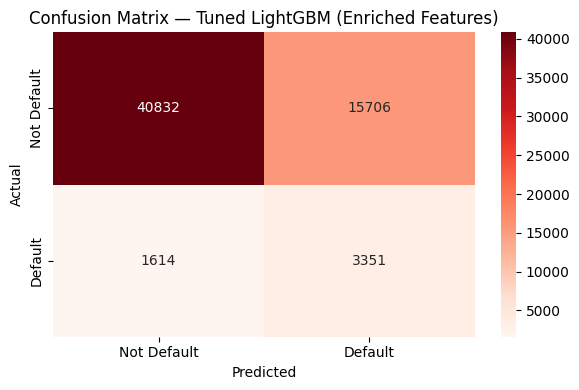

saved


In [9]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import confusion_matrix, roc_auc_score, average_precision_score


pre = saved_model.named_steps['preprocessor']
print('raw input features :', len(pre.feature_names_in_))              
print('encoded inputs     :', pre.transform(X_test.head(5)).shape[1])  
p = saved_model.predict_proba(X_test)[:, 1]
print('test ROC-AUC       :', round(roc_auc_score(y_test, p), 4))      
print('test PR-AUC        :', round(average_precision_score(y_test, p), 4)) 
print('test size / positives:', len(y_test), int(y_test.sum()))       


def op_point(thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return dict(threshold=thr, TN=tn, FP=fp, FN=fn, TP=tp,
                recall=tp/(tp+fn), precision=tp/(tp+fp), specificity=tn/(tn+fp),
                F1=2*tp/(2*tp+fp+fn), flagged_pct=100*(tp+fp)/len(y_test))
table = pd.DataFrame([op_point(t) for t in (0.3, 0.4, 0.5, 0.6)]).round(3)
print(table.to_string(index=False))


cm = confusion_matrix(y_test, (p >= 0.5).astype(int))
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
            xticklabels=['Not Default', 'Default'], yticklabels=['Not Default', 'Default'])
plt.title('Confusion Matrix — Tuned LightGBM (Enriched Features)')
plt.ylabel('Actual'); plt.xlabel('Predicted'); plt.tight_layout()
os.makedirs('../models', exist_ok=True)
plt.savefig('../models/fig11_confusion_enriched.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()


np.save('../models/p_lgbm_tuned.npy', p)
np.save('../models/y_test.npy', np.asarray(y_test))
print('saved')

In [10]:
class MLP(nn.Module):
    def __init__(self, d_in, hidden=(256, 128, 64), p=0.3):
        super().__init__()
        layers, d = [], d_in
        for h in hidden:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(p)]
            d = h
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x).squeeze(1)

def predict(model, X, bs=8192):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            xb = torch.from_numpy(X[i:i+bs]).to(device)
            out.append(torch.sigmoid(model(xb)).cpu().numpy())
    return np.concatenate(out)

def train_mlp(seed, epochs=40, patience=5, bs=1024, lr=1e-3, wd=1e-4, verbose=True):
    torch.manual_seed(seed); np.random.seed(seed)
    model = MLP(Xtr_f.shape[1]).to(device)

    # neural-net equivalent of scale_pos_weight (handles the 92/8 imbalance)
    pos_w = torch.tensor((1 - ytr_f.mean()) / ytr_f.mean(), dtype=torch.float32, device=device)
    lossf = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=2)

    Xt, yt = torch.from_numpy(Xtr_f), torch.from_numpy(ytr_f)
    best, best_state, bad, hist = 0, None, 0, []

    for ep in range(epochs):
        model.train()
        perm, tot = torch.randperm(len(Xt)), 0
        for i in range(0, len(Xt), bs):
            idx = perm[i:i+bs]
            xb, yb = Xt[idx].to(device), yt[idx].to(device)
            opt.zero_grad()
            loss = lossf(model(xb), yb)
            loss.backward()
            opt.step()
            tot += loss.item() * len(idx)

        va = roc_auc_score(yva, predict(model, Xva))
        sched.step(va)
        hist.append((tot / len(Xt), va))
        if verbose:
            print(f'seed {seed} | epoch {ep+1:02d} | loss {tot/len(Xt):.4f} | val AUC {va:.4f}')

        if va > best:
            best, bad = va, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                if verbose: print('early stopping')
                break

    model.load_state_dict(best_state)
    return model, hist

seed 42 | epoch 01 | loss 1.1237 | val AUC 0.7484
seed 42 | epoch 02 | loss 1.0861 | val AUC 0.7484
seed 42 | epoch 03 | loss 1.0763 | val AUC 0.7518
seed 42 | epoch 04 | loss 1.0700 | val AUC 0.7501
seed 42 | epoch 05 | loss 1.0630 | val AUC 0.7540
seed 42 | epoch 06 | loss 1.0585 | val AUC 0.7531
seed 42 | epoch 07 | loss 1.0525 | val AUC 0.7525
seed 42 | epoch 08 | loss 1.0485 | val AUC 0.7525
seed 42 | epoch 09 | loss 1.0363 | val AUC 0.7514
seed 42 | epoch 10 | loss 1.0312 | val AUC 0.7513
early stopping

MLP test ROC-AUC: 0.7619  (52s)


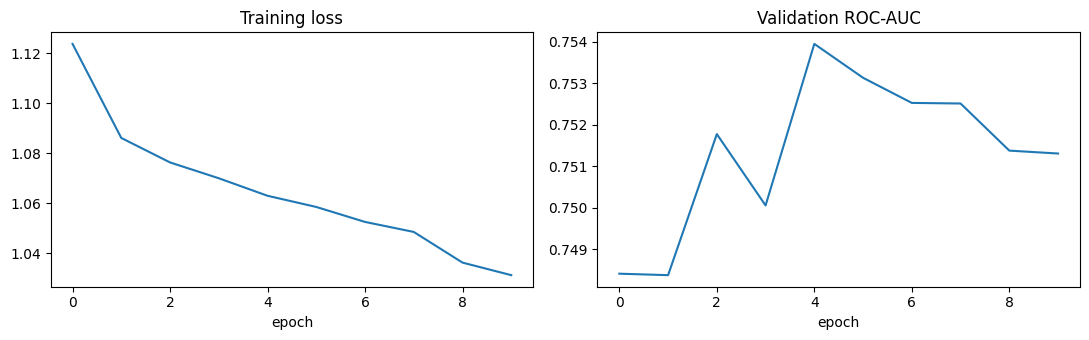

In [11]:
t = time.time()
mlp, hist = train_mlp(SEED)
probs['MLP (PyTorch)'] = predict(mlp, Xte)
family['MLP (PyTorch)'] = 'Deep Learning'
timing['MLP (PyTorch)'] = time.time() - t
print(f'\nMLP test ROC-AUC: {roc_auc_score(yte, probs["MLP (PyTorch)"]):.4f}  ({timing["MLP (PyTorch)"]:.0f}s)')

h = np.array(hist)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h[:, 0]); ax[0].set_title('Training loss');      ax[0].set_xlabel('epoch')
ax[1].plot(h[:, 1]); ax[1].set_title('Validation ROC-AUC'); ax[1].set_xlabel('epoch')
plt.tight_layout(); plt.show()

In [12]:
extra = [train_mlp(s, verbose=False)[0] for s in (1, 2)]
p_ens = np.mean([probs['MLP (PyTorch)']] + [predict(m, Xte) for m in extra], axis=0)
probs['MLP ensemble (3 seeds)'] = p_ens
family['MLP ensemble (3 seeds)'] = 'Deep Learning'

rank = lambda p: rankdata(p) / len(p)
probs['Blend: LightGBM + MLP'] = 0.5 * rank(probs['LightGBM (tuned)']) + 0.5 * rank(p_ens)
family['Blend: LightGBM + MLP'] = 'Hybrid'

for k in ['MLP ensemble (3 seeds)', 'Blend: LightGBM + MLP']:
    print(f'{k:25s} ROC-AUC {roc_auc_score(yte, probs[k]):.4f}')

MLP ensemble (3 seeds)    ROC-AUC 0.7635
Blend: LightGBM + MLP     ROC-AUC 0.7705


In [ ]:

reference = {
    'Logistic Regression': 0.757,
    'Random Forest': 0.757,
    'XGBoost': 0.764,
}

rows = [{'Model': n, 'Family': 'Classical ML', 'ROC-AUC': v, 'PR-AUC': None}
        for n, v in reference.items()]
rows += [{'Model': n, 'Family': family[n],
          'ROC-AUC': round(roc_auc_score(yte, p), 4),
          'PR-AUC': round(average_precision_score(yte, p), 4)}
         for n, p in probs.items()]

comp = pd.DataFrame(rows).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
display(comp)

,Model,Family,ROC-AUC,PR-AUC
0,Blend: LightGBM + MLP,Hybrid,0.7705,0.2649
1,LightGBM (tuned),Classical ML,0.7696,0.2634
2,XGBoost,Classical ML,0.7640,NaN
3,MLP ensemble (3 seeds),Deep Learning,0.7635,0.2536
4,MLP (PyTorch),Deep Learning,0.7619,0.2485
5,Random Forest,Classical ML,0.7570,NaN
6,Logistic Regression,Classical ML,0.7570,NaN


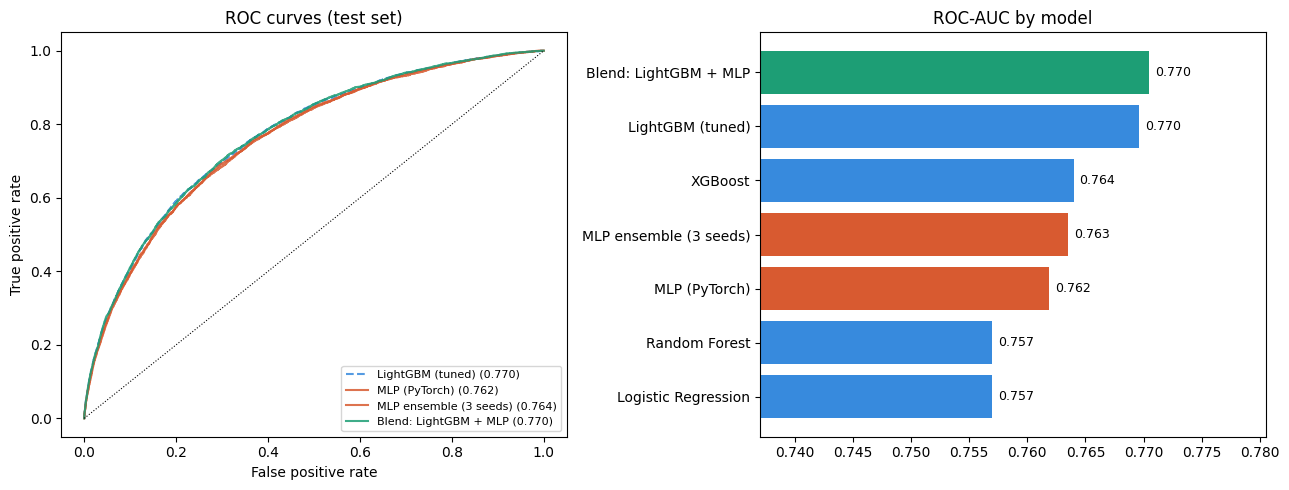

In [14]:
colors = {'Classical ML': '#378ADD', 'Deep Learning': '#D85A30', 'Hybrid': '#1D9E75'}
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

for n, p in probs.items():
    fpr, tpr, _ = roc_curve(yte, p)
    ax[0].plot(fpr, tpr, color=colors[family[n]], alpha=.85,
               ls='--' if family[n] == 'Classical ML' else '-',
               label=f'{n} ({roc_auc_score(yte, p):.3f})')
ax[0].plot([0, 1], [0, 1], 'k:', lw=.8)
ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate')
ax[0].set_title('ROC curves (test set)'); ax[0].legend(fontsize=8, loc='lower right')

c = comp.sort_values('ROC-AUC')
ax[1].barh(c['Model'], c['ROC-AUC'], color=[colors[f] for f in c['Family']])
ax[1].set_xlim(c['ROC-AUC'].min() - 0.02, c['ROC-AUC'].max() + 0.01)
ax[1].set_title('ROC-AUC by model')
for i, v in enumerate(c['ROC-AUC']):
    ax[1].text(v + 0.0005, i, f'{v:.3f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('roc_comparison.png', dpi=150)
plt.show()

In [1]:
import gc, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from scipy import sparse
from scipy.stats import rankdata, norm
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, recall_score, precision_score, f1_score
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression as PlattScaler
from lightgbm import LGBMClassifier
warnings.filterwarnings('ignore')

SEED = 42
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATA_DIR = '../data' if os.path.exists('../data/application_train.csv') else 'data'

df7 = pd.read_pickle(f'{DATA_DIR}/home_credit_7tables_merged.pkl')
aux_prefixes = ('BUREAU_', 'PREV_', 'INSTAL_', 'POS_', 'CC_', 'NO_')
aux_c = [c for c in df7.columns if c.startswith(aux_prefixes)]
miss7 = df7.drop(columns=aux_c).isnull().sum() / len(df7) * 100
drop7 = [c for c in miss7[miss7 > 40].index if c not in ('EXT_SOURCE_1', 'EXT_SOURCE_MEAN', 'EXT_SOURCE_STD')]
df7.drop(columns=drop7 + ['SK_ID_CURR'], inplace=True, errors='ignore')

df7['AGE_YEARS'] = df7['DAYS_BIRTH'] / -365.0
df7['DAYS_EMPLOYED_ANOM'] = (df7['DAYS_EMPLOYED'] == 365243).astype(int)
df7['DAYS_EMPLOYED'] = df7['DAYS_EMPLOYED'].replace(365243, 0)
df7['YEARS_EMPLOYED'] = (df7['DAYS_EMPLOYED'] / -365.0).clip(lower=0)
df7['CREDIT_INCOME_RATIO']  = df7['AMT_CREDIT']  / (df7['AMT_INCOME_TOTAL'] + 1.0)
df7['ANNUITY_INCOME_RATIO'] = df7['AMT_ANNUITY'] / (df7['AMT_INCOME_TOTAL'] + 1.0)
df7['CREDIT_GOODS_RATIO']   = df7['AMT_CREDIT']  / (df7['AMT_GOODS_PRICE'] + 1.0)
df7['INCOME_PER_PERSON']    = df7['AMT_INCOME_TOTAL'] / (df7['CNT_FAM_MEMBERS'] + 1.0)
df7['CREDIT_TO_ANNUITY_RATIO'] = df7['AMT_CREDIT'] / (df7['AMT_ANNUITY'] + 1.0)
ext_c = [c for c in ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3'] if c in df7.columns]
df7['EXT_SOURCE_MEAN'] = df7[ext_c].mean(axis=1)
df7['EXT_SOURCE_STD']  = df7[ext_c].std(axis=1)
df7.drop(columns=['DAYS_BIRTH', 'DAYS_EMPLOYED'], inplace=True, errors='ignore')

X7 = df7.drop('TARGET', axis=1); y7 = df7['TARGET']
cat7 = X7.select_dtypes(exclude=np.number).columns.tolist()
num7 = X7.select_dtypes(include=np.number).columns.tolist()
X7[cat7] = X7[cat7].fillna('missing').astype(str)

X_train7, X_test7, y_train7, y_test7 = train_test_split(X7, y7, test_size=0.2, random_state=42, stratify=y7)
prep7 = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num7),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat7)
])

def to_dense32(a):
    a = a.toarray() if sparse.issparse(a) else np.asarray(a)
    return np.clip(a, -10, 10).astype(np.float32)

X_tr7, X_val7, y_tr7, y_val7 = train_test_split(X_train7, y_train7, test_size=0.1, stratify=y_train7, random_state=SEED)
X_tr7_p  = to_dense32(prep7.fit_transform(X_tr7))
X_val7_p = to_dense32(prep7.transform(X_val7))
X_te7_p  = to_dense32(prep7.transform(X_test7))
y_tr_np  = np.asarray(y_tr7, dtype=np.float32)
y_val_np = np.asarray(y_val7, dtype=np.float32)
y_te_np  = np.asarray(y_test7, dtype=np.float32)
print(f'7-Table Deep Learning Tensors Ready on {device} -> {X_tr7_p.shape[1]} input features.')

7-Table Deep Learning Tensors Ready on cpu -> 260 input features.


In [2]:
class MLP(nn.Module):
    def __init__(self, n_in, hidden=(256, 128, 64), dropout=0.3):
        super().__init__()
        layers, prev = [], n_in
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x).squeeze(1)

class ResNetBlock(nn.Module):
    def __init__(self, d_model, dropout=0.25):
        super().__init__()
        self.block = nn.Sequential(
            nn.BatchNorm1d(d_model), nn.SiLU(), nn.Linear(d_model, d_model),
            nn.BatchNorm1d(d_model), nn.SiLU(), nn.Dropout(dropout),
            nn.Linear(d_model, d_model), nn.Dropout(dropout),
        )
    def forward(self, x):
        return x + self.block(x)

class TabularResNet(nn.Module):
    def __init__(self, n_in, d_model=256, n_blocks=3, dropout=0.25):
        super().__init__()
        self.input_proj = nn.Linear(n_in, d_model)
        self.blocks = nn.ModuleList([ResNetBlock(d_model, dropout) for _ in range(n_blocks)])
        self.head = nn.Sequential(nn.BatchNorm1d(d_model), nn.SiLU(), nn.Linear(d_model, 1))
    def forward(self, x):
        h = self.input_proj(x)
        for blk in self.blocks:
            h = blk(h)
        return self.head(h).squeeze(1)

class TabularFTAttention(nn.Module):
    def __init__(self, n_in, n_tokens=16, d_token=64, n_heads=4, n_layers=2, dropout=0.2):
        super().__init__()
        self.n_tokens, self.d_token = n_tokens, d_token
        self.tokenizer = nn.Sequential(nn.Linear(n_in, n_tokens * d_token), nn.LayerNorm(n_tokens * d_token))
        enc_layer = nn.TransformerEncoderLayer(d_model=d_token, nhead=n_heads, dim_feedforward=d_token*2,
                                               dropout=dropout, activation='gelu', batch_first=True, norm_first=True)
        self.transformer = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.head = nn.Sequential(nn.LayerNorm(d_token), nn.Linear(d_token, 1))
    def forward(self, x):
        tokens = self.tokenizer(x).view(x.size(0), self.n_tokens, self.d_token)
        return self.head(self.transformer(tokens).mean(dim=1)).squeeze(1)

def predict_proba(model, X, batch=4096):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(X), batch):
            xb = torch.from_numpy(X[i:i + batch]).to(device)
            out.append(torch.sigmoid(model(xb)).cpu().numpy())
    return np.concatenate(out)

def train_deep_tabular(model_cls, model_kwargs, X_tr_arr, y_tr_arr, X_va_arr, y_va_arr,
                       seed=42, lr=1e-3, weight_decay=1e-4, max_epochs=30, patience=5, batch_size=1024):
    torch.manual_seed(seed); np.random.seed(seed)
    model = model_cls(X_tr_arr.shape[1], **model_kwargs).to(device)
    pos_weight = torch.tensor((y_tr_arr == 0).sum() / (y_tr_arr == 1).sum(), dtype=torch.float32, device=device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)
    g = torch.Generator().manual_seed(seed)
    loader = DataLoader(TensorDataset(torch.from_numpy(X_tr_arr), torch.from_numpy(y_tr_arr)),
                        batch_size=batch_size, shuffle=True, drop_last=True, generator=g)
    best_auc, best_state, bad = 0.0, None, 0
    for epoch in range(1, max_epochs + 1):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(); loss = criterion(model(xb), yb); loss.backward(); optimizer.step()
        val_auc = roc_auc_score(y_va_arr, predict_proba(model, X_va_arr))
        scheduler.step(val_auc)
        if val_auc > best_auc:
            best_auc, bad = val_auc, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)
    return model, best_auc

# 1. Tuned 7-Table LightGBM
t0 = time.time()
lgbm_7 = LGBMClassifier(n_estimators=400, max_depth=8, num_leaves=31, learning_rate=0.05,
                        subsample=0.8, colsample_bytree=0.85, scale_pos_weight=11, random_state=42, verbose=-1, n_jobs=-1)
lgbm_7.fit(X_tr7_p, y_tr_np)
lgbm7_probs = lgbm_7.predict_proba(X_te7_p)[:, 1]
print(f'Tuned 7-Table LightGBM -> Test ROC-AUC: {roc_auc_score(y_te_np, lgbm7_probs):.4f} | PR-AUC: {average_precision_score(y_te_np, lgbm7_probs):.4f} ({time.time()-t0:.1f}s)')

# 2. 3-Seed MLP Ensemble
t0 = time.time()
mlp7_probs = np.mean([predict_proba(train_deep_tabular(MLP, {'hidden': (256, 128, 64), 'dropout': 0.3}, X_tr7_p, y_tr_np, X_val7_p, y_val_np, seed=s)[0], X_te7_p) for s in [42, 7, 123]], axis=0)
print(f'7-Table MLP (3-Seed)   -> Test ROC-AUC: {roc_auc_score(y_te_np, mlp7_probs):.4f} | PR-AUC: {average_precision_score(y_te_np, mlp7_probs):.4f} ({time.time()-t0:.1f}s)')

# 3. 3-Seed Tabular ResNet Ensemble
t0 = time.time()
resnet7_probs = np.mean([predict_proba(train_deep_tabular(TabularResNet, {'d_model': 256, 'n_blocks': 3, 'dropout': 0.25}, X_tr7_p, y_tr_np, X_val7_p, y_val_np, seed=s)[0], X_te7_p) for s in [42, 7, 123]], axis=0)
print(f'7-Table Tabular ResNet -> Test ROC-AUC: {roc_auc_score(y_te_np, resnet7_probs):.4f} | PR-AUC: {average_precision_score(y_te_np, resnet7_probs):.4f} ({time.time()-t0:.1f}s)')

# 4. FT-Attention Transformer
t0 = time.time()
m_ftt, _ = train_deep_tabular(TabularFTAttention, {'n_tokens': 16, 'd_token': 64, 'n_heads': 4, 'n_layers': 2, 'dropout': 0.2}, X_tr7_p, y_tr_np, X_val7_p, y_val_np, seed=42)
ftt7_probs = predict_proba(m_ftt, X_te7_p)
print(f'7-Table FT-Transformer -> Test ROC-AUC: {roc_auc_score(y_te_np, ftt7_probs):.4f} | PR-AUC: {average_precision_score(y_te_np, ftt7_probs):.4f} ({time.time()-t0:.1f}s)')

# 5. Rank-Averaged Hybrid Blend
r_lgb = rankdata(lgbm7_probs) / len(lgbm7_probs)
r_res = rankdata(resnet7_probs) / len(resnet7_probs)
r_mlp = rankdata(mlp7_probs) / len(mlp7_probs)
hybrid7_probs = 0.55 * r_lgb + 0.25 * r_res + 0.20 * r_mlp
print(f'7-Table Hybrid Blend   -> Test ROC-AUC: {roc_auc_score(y_te_np, hybrid7_probs):.4f} | PR-AUC: {average_precision_score(y_te_np, hybrid7_probs):.4f}')

Tuned 7-Table LightGBM -> Test ROC-AUC: 0.7862 | PR-AUC: 0.2832 (11.9s)
7-Table MLP (3-Seed)   -> Test ROC-AUC: 0.7785 | PR-AUC: 0.2780 (280.5s)
7-Table Tabular ResNet -> Test ROC-AUC: 0.7799 | PR-AUC: 0.2766 (597.2s)
7-Table FT-Transformer -> Test ROC-AUC: 0.7763 | PR-AUC: 0.2675 (1056.5s)
7-Table Hybrid Blend   -> Test ROC-AUC: 0.7876 | PR-AUC: 0.2870


In [3]:
def compute_midrank(x):
    J = np.argsort(x); Z = x[J]; N = len(x); T = np.zeros(N, dtype=np.float64); i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]: j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1; i = j
    T2 = np.empty(N, dtype=np.float64); T2[J] = T
    return T2

def fast_delong_components(y_true, y_prob):
    y_true = np.asarray(y_true, dtype=int)
    pos, neg = y_prob[y_true == 1], y_prob[y_true == 0]
    m, n = len(pos), len(neg)
    tx, ty, tz = compute_midrank(pos), compute_midrank(neg), compute_midrank(np.concatenate([pos, neg]))
    auc = (tz[:m].sum() - m * (m + 1) / 2.0) / (m * n)
    return auc, (tz[:m] - tx) / n, 1.0 - (tz[m:] - ty) / m

def paired_delong_test(y_true, prob_a, prob_b):
    auc_a, v01_a, v10_a = fast_delong_components(y_true, prob_a)
    auc_b, v01_b, v10_b = fast_delong_components(y_true, prob_b)
    S = (np.cov(v01_a, v01_b) / len(v01_a)) + (np.cov(v10_a, v10_b) / len(v10_a))
    var_diff = S[0, 0] + S[1, 1] - 2 * S[0, 1]
    z_stat = (auc_a - auc_b) / np.sqrt(max(var_diff, 1e-12))
    p_val = 2.0 * (1.0 - norm.cdf(abs(z_stat)))
    return auc_a, np.sqrt(S[0, 0]), auc_b, z_stat, p_val

model_preds_dict = {
    '1. Hybrid Blend (LGBM + ResNet + MLP)': hybrid7_probs,
    '2. Tuned LightGBM (7-Table)': lgbm7_probs,
    '3. Tabular ResNet (3-Seed)': resnet7_probs,
    '4. PyTorch MLP (3-Seed)': mlp7_probs,
    '5. FT-Transformer (Attention)': ftt7_probs,
}

stat_rows = []
for name, probs_arr in model_preds_dict.items():
    auc_m, se_m, auc_ref, z_s, p_v = paired_delong_test(y_te_np, probs_arr, lgbm7_probs)
    stat_rows.append({
        'Model': name, 'Test ROC-AUC': round(auc_m, 4),
        '95% CI (DeLong)': f'[{auc_m - 1.96*se_m:.4f}, {auc_m + 1.96*se_m:.4f}]',
        'Test PR-AUC': round(average_precision_score(y_te_np, probs_arr), 4),
        'Delta vs 7-Tab LGBM': f'{auc_m - auc_ref:+.4f}',
        'DeLong z-stat': round(z_s, 3),
        'DeLong p-value': f'{p_v:.4e}' if p_v < 0.001 else round(p_v, 4)
    })
display(pd.DataFrame(stat_rows))

,Model,Test ROC-AUC,95% CI (DeLong),Test PR-AUC,Delta vs 7-Tab LGBM,DeLong z-stat,DeLong p-value
0,1. Hybrid Blend (LGBM + ResNet + MLP),0.7876,"[0.7811, 0.7942]",0.2870,+0.0015,2.323,0.0202
1,2. Tuned LightGBM (7-Table),0.7862,"[0.7796, 0.7927]",0.2832,+0.0000,0.000,1.0
2,3. Tabular ResNet (3-Seed),0.7799,"[0.7732, 0.7865]",0.2766,-0.0063,-4.474,7.6653e-06
3,4. PyTorch MLP (3-Seed),0.7785,"[0.7718, 0.7852]",0.2780,-0.0077,-5.258,1.4558e-07
4,5. FT-Transformer (Attention),0.7763,"[0.7696, 0.7830]",0.2675,-0.0099,-6.298,3.0221e-10


,Method,ROC-AUC,Brier Score,ECE,Mean PD
0,Uncalibrated LightGBM (scale_pos_weight=11),0.7862,0.1666,0.2822,0.3630
1,Platt Scaling (Sigmoid Calibrated),0.7862,0.0661,0.0044,0.0795
2,Isotonic Regression Calibrated,0.7857,0.0659,0.0018,0.0796


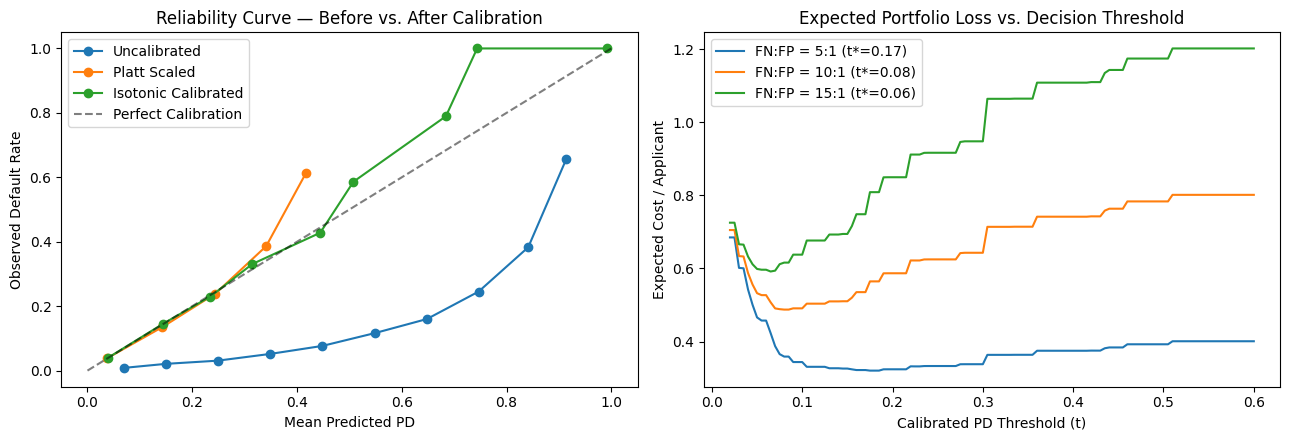

,FN:FP Cost Ratio,Bayes Threshold,Optimal t*,Min Expected Cost,Recall at t*,Precision at t*,F1 at t*
0,5:1,0.167,0.175,0.3205,0.395,0.295,0.338
1,10:1,0.091,0.080,0.4875,0.681,0.193,0.301
2,15:1,0.062,0.065,0.5918,0.791,0.159,0.264


In [4]:
def expected_calibration_error(y_true, y_prob, n_bins=10):
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    bin_ids = np.digitize(y_prob, bins[1:-1])
    return sum(( (bin_ids == b).sum() / len(y_true) ) * abs(y_true[bin_ids == b].mean() - y_prob[bin_ids == b].mean())
               for b in range(n_bins) if np.any(bin_ids == b))

val_lgbm_probs = lgbm_7.predict_proba(X_val7_p)[:, 1]
iso_cal = IsotonicRegression(out_of_bounds='clip').fit(val_lgbm_probs, y_val_np)
lgbm7_probs_iso = iso_cal.transform(lgbm7_probs)
platt_cal = PlattScaler().fit(val_lgbm_probs.reshape(-1, 1), y_val_np)
lgbm7_probs_platt = platt_cal.predict_proba(lgbm7_probs.reshape(-1, 1))[:, 1]

cal_summary = pd.DataFrame([
    {'Method': 'Uncalibrated LightGBM (scale_pos_weight=11)', 'ROC-AUC': round(roc_auc_score(y_te_np, lgbm7_probs), 4),
     'Brier Score': round(brier_score_loss(y_te_np, lgbm7_probs), 4), 'ECE': round(expected_calibration_error(y_te_np, lgbm7_probs), 4), 'Mean PD': round(float(lgbm7_probs.mean()), 4)},
    {'Method': 'Platt Scaling (Sigmoid Calibrated)', 'ROC-AUC': round(roc_auc_score(y_te_np, lgbm7_probs_platt), 4),
     'Brier Score': round(brier_score_loss(y_te_np, lgbm7_probs_platt), 4), 'ECE': round(expected_calibration_error(y_te_np, lgbm7_probs_platt), 4), 'Mean PD': round(float(lgbm7_probs_platt.mean()), 4)},
    {'Method': 'Isotonic Regression Calibrated', 'ROC-AUC': round(roc_auc_score(y_te_np, lgbm7_probs_iso), 4),
     'Brier Score': round(brier_score_loss(y_te_np, lgbm7_probs_iso), 4), 'ECE': round(expected_calibration_error(y_te_np, lgbm7_probs_iso), 4), 'Mean PD': round(float(lgbm7_probs_iso.mean()), 4)}
])
display(cal_summary)

thresholds = np.linspace(0.02, 0.60, 117)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for label, p_arr in [('Uncalibrated', lgbm7_probs), ('Platt Scaled', lgbm7_probs_platt), ('Isotonic Calibrated', lgbm7_probs_iso)]:
    frac_pos, mean_pred = calibration_curve(y_te_np, p_arr, n_bins=10)
    axes[0].plot(mean_pred, frac_pos, marker='o', label=label)
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Perfect Calibration')
axes[0].set_title('Reliability Curve — Before vs. After Calibration'); axes[0].set_xlabel('Mean Predicted PD'); axes[0].set_ylabel('Observed Default Rate'); axes[0].legend()

cost_rows = []
for r in [5, 10, 15]:
    costs = np.array([((r * (( (lgbm7_probs_iso >= t) == 0 ) & (y_te_np == 1)).sum() + (( (lgbm7_probs_iso >= t) == 1 ) & (y_te_np == 0)).sum()) / len(y_te_np)) for t in thresholds])
    best_i = np.argmin(costs); t_opt = thresholds[best_i]; p_opt = (lgbm7_probs_iso >= t_opt).astype(int)
    axes[1].plot(thresholds, costs, label=f'FN:FP = {r}:1 (t*={t_opt:.2f})')
    cost_rows.append({'FN:FP Cost Ratio': f'{r}:1', 'Bayes Threshold': round(1/(1+r), 3), 'Optimal t*': round(float(t_opt), 3),
                      'Min Expected Cost': round(float(costs[best_i]), 4), 'Recall at t*': round(float(recall_score(y_te_np, p_opt)), 3),
                      'Precision at t*': round(float(precision_score(y_te_np, p_opt)), 3), 'F1 at t*': round(float(f1_score(y_te_np, p_opt)), 3)})
axes[1].set_title('Expected Portfolio Loss vs. Decision Threshold'); axes[1].set_xlabel('Calibrated PD Threshold (t)'); axes[1].set_ylabel('Expected Cost / Applicant'); axes[1].legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame(cost_rows))